# NYC Department of Buildings permit applications for apartment alterations
**Group Members** Ugochinyere Megwa, Sneha Sachin Shenoy, Álvaro Miñé

**DAY 1 Cleaning and EDA**

### Goal

What drives the cost of apartment renovations in New York City, and how has it changed over time and across boroughs?

## Overview

This analysis explores 13,500 apartment renovation permits filed with the NYC Department of Buildings to understand how renovation costs vary by borough, job type, zoning and time, and which factors are most associated with higher-cost projects. 



# Setup and Data

## 0.1 Libararies

Import necessary modules 

In [426]:
# %pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

In [427]:
#import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
from pathlib import Path
from matplotlib.ticker import FuncFormatter, MaxNLocator
import matplotlib.dates as mdates


### Collecting the Data

We collected the Data from Kaggle. The NYC Housing dataset contains information about the New York City Housing and Preservation Department's (HPD) affordable housing development projects. It includes data on building characteristics, affordability levels, location, and ownership information for all properties in the dataset.

In [428]:
df = pd.read_csv('../figures/apartment_data.csv')

In [429]:
df.head

<bound method NDFrame.head of            Job #    Borough House #          Street Name  Block  Lot    Bin #  \
0      123768976  MANHATTAN    1598           2ND AVENUE   1545   49  1049907   
1      140922893  MANHATTAN     160              E 89 ST   1517   43  1048094   
2      301773579   BROOKLYN      65         GATES AVENUE   1962   86  3056039   
3      301976057   BROOKLYN    1401         OCEAN AVENUE   7584   35  3206621   
4      301989276   BROOKLYN     154         NOBLE STREET   2573   10  3065099   
...          ...        ...     ...                  ...    ...  ...      ...   
19608  122923649  MANHATTAN     315     WEST 33RD STREET    757   22  1013552   
19609  121090112  MANHATTAN     110         DUANE STREET    150   22  1001645   
19610  102937342  MANHATTAN     166          BANK STREET    638    4  1078335   
19611  200838558      BRONX    2762  KINGSBRIDGE TERRACE   3253   90  2015521   
19612  301429158   BROOKLYN     802        HOWARD AVENUE   3565   42  3081797  

In [430]:
df.info

<bound method DataFrame.info of            Job #    Borough House #          Street Name  Block  Lot    Bin #  \
0      123768976  MANHATTAN    1598           2ND AVENUE   1545   49  1049907   
1      140922893  MANHATTAN     160              E 89 ST   1517   43  1048094   
2      301773579   BROOKLYN      65         GATES AVENUE   1962   86  3056039   
3      301976057   BROOKLYN    1401         OCEAN AVENUE   7584   35  3206621   
4      301989276   BROOKLYN     154         NOBLE STREET   2573   10  3065099   
...          ...        ...     ...                  ...    ...  ...      ...   
19608  122923649  MANHATTAN     315     WEST 33RD STREET    757   22  1013552   
19609  121090112  MANHATTAN     110         DUANE STREET    150   22  1001645   
19610  102937342  MANHATTAN     166          BANK STREET    638    4  1078335   
19611  200838558      BRONX    2762  KINGSBRIDGE TERRACE   3253   90  2015521   
19612  301429158   BROOKLYN     802        HOWARD AVENUE   3565   42  3081797

In [431]:
df_clean = df.copy()

In [432]:
# information in columns
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Job #,19613.0,NaN,NaN,NaN,162426590.843063,91577222.331873,102133077.0,104824424.0,121711228.0,140825846.0,540180276.0
Borough,19613,5,MANHATTAN,15341,NaN,NaN,NaN,NaN,NaN,NaN,NaN
House #,19613,1959,200,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Street Name,19613,2580,PARK AVENUE,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Block,19613.0,NaN,NaN,NaN,1551.725794,1550.780753,0.0,816.0,1245.0,1576.0,16278.0
Lot,19613.0,NaN,NaN,NaN,1261.811197,2764.626109,0.0,17.0,36.0,66.0,9007.0
Bin #,19613.0,NaN,NaN,NaN,1506364.505328,931999.249497,1000043.0,1028758.0,1046983.0,1084564.0,5860016.0
Job Type,19613,3,A2,18126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Community - Board,19613.0,NaN,NaN,NaN,151.269005,90.115653,101.0,105.0,107.0,111.0,503.0
Curb Cut,16,1,X,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN


First look at data uncleaned

In [433]:
# finding columns to remove
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19613 entries, 0 to 19612
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Job #                   19613 non-null  int64
 1   Borough                 19613 non-null  str  
 2   House #                 19613 non-null  str  
 3   Street Name             19613 non-null  str  
 4   Block                   19613 non-null  int64
 5   Lot                     19613 non-null  int64
 6   Bin #                   19613 non-null  int64
 7   Job Type                19613 non-null  str  
 8   Community - Board       19613 non-null  int64
 9   Curb Cut                16 non-null     str  
 10  Fully Permitted         15625 non-null  str  
 11  Initial Cost            19613 non-null  str  
 12  Proposed Zoning Sqft    19613 non-null  int64
 13  Horizontal Enlrgmt      163 non-null    str  
 14  Vertical Enlrgmt        242 non-null    str  
 15  Enlargement SQ Footage  19613 

In [434]:
#removing columns with over 95% missing values
df = df.drop(['Curb Cut', 'Proposed Zoning Sqft', 'Horizontal Enlrgmt', 'Vertical Enlrgmt', 'Enlargement SQ Footage' ], axis=1)


In [435]:
df.isnull().sum(axis=1)

0        1
1        0
2        0
3        1
4        0
        ..
19608    0
19609    0
19610    0
19611    1
19612    1
Length: 19613, dtype: int64

In [436]:
#checking for rows with more than 2 missing values
df[df.isnull().sum(axis=1) > 0]

,Job #,Borough,House #,Street Name,Block,Lot,Bin #,Job Type,Community - Board,Fully Permitted,Initial Cost,Zoning Dist1,Job Description
0,123768976,MANHATTAN,1598,2ND AVENUE,1545,49,1049907,A2,108,NaN,"$65,000.00",C1-9,INTERIOR RENOVATION TO COMBINE APARTMENT 2E AN...
3,301976057,BROOKLYN,1401,OCEAN AVENUE,7584,35,3206621,A2,314,02/28/2006,"$75,000.00",NaN,COMBINING OF APARTMENT 4A &amp; 4L.NO CHANGEIN...
11,302022656,BROOKLYN,6,2 STREET,460,2,3007811,A2,306,04/23/2008,"$60,000.00",NaN,RENOVATE EXISTING LOWER DUPLEX APARTMENT. NO C...
12,102614048,MANHATTAN,730,PARK AVENUE,1385,37,1041333,A2,108,05/10/2000,"$75,000.00",NaN,Minor renovation to existing apartment to incl...
13,302026849,BROOKLYN,1054,WILLOUGHBY AVENUE,3208,11,3325441,A2,304,NaN,"$40,000.00",R6,Application being filed to renovate existing s...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19579,104477870,MANHATTAN,160,CENTRAL PARK SOUTH,1011,7501,1023760,A2,105,09/15/2006,"$85,000.00",NaN,RENOVATION OF AN EXISTING APARTMENTON THE 9TH ...
19583,321998326,BROOKLYN,126,DEAN STREET,194,32,3001265,A1,302,NaN,"$40,000.00",R6,REMOVAL AND INSTALLATION OF INTERIOR PARTITION...
19584,302221138,BROOKLYN,234,WASHINGTON AVENUE,1917,32,3055065,A1,302,NaN,"$75,000.00",R6,Proposed to convert one class 'A' apartment an...
19611,200838558,BRONX,2762,KINGSBRIDGE TERRACE,3253,90,2015521,A2,208,NaN,"$40,000.00",R6,Proposed to renovate existing apartments. No c...


In [437]:
#checking and removing duplicates
n_duplicates = df_clean.duplicated().sum()
print(n_duplicates)
df_clean = df.drop_duplicates()

6104


In [438]:
# resetting the index
df_clean = df.reset_index(drop=True)

In [439]:
#formatting the Job_Description to all be capital
df_clean = df.map(lambda x: x.upper() if isinstance(x, str) else x)

In [440]:
#formatting cost to remove '$' and ','
df_clean['Initial Cost'] = pd.to_numeric(
    df_clean['Initial Cost']
    .astype('string')
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

df_clean['Initial Cost Original'] = df_clean['Initial Cost'].copy()

df_clean

,Job #,Borough,House #,Street Name,Block,Lot,Bin #,Job Type,Community - Board,Fully Permitted,Initial Cost,Zoning Dist1,Job Description,Initial Cost Original
0,123768976,MANHATTAN,1598,2ND AVENUE,1545,49,1049907,A2,108,NaN,65000.0,C1-9,INTERIOR RENOVATION TO COMBINE APARTMENT 2E AN...,65000.0
1,140922893,MANHATTAN,160,E 89 ST,1517,43,1048094,A2,108,07/14/2020,85000.0,R8B,HEREBY FILING APPLICATION FOR THE INTERIOR REN...,85000.0
2,301773579,BROOKLYN,65,GATES AVENUE,1962,86,3056039,A1,302,05/23/2007,60000.0,R6,CHANGE EXISTING FOUR STORY AND BASEMENT BRICK ...,60000.0
3,301976057,BROOKLYN,1401,OCEAN AVENUE,7584,35,3206621,A2,314,02/28/2006,75000.0,NaN,COMBINING OF APARTMENT 4A &AMP; 4L.NO CHANGEIN...,75000.0
4,301989276,BROOKLYN,154,NOBLE STREET,2573,10,3065099,A1,301,09/29/2006,40000.0,C4-3,NEW C OF O FOR EXISTING BUILDING. NEW DUPLEX A...,40000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19608,122923649,MANHATTAN,315,WEST 33RD STREET,757,22,1013552,A2,104,03/21/2017,60000.0,C6-4,RENOVATION OF APARTMENTS 8N &AMP; 12A. ARCHITE...,60000.0
19609,121090112,MANHATTAN,110,DUANE STREET,150,22,1001645,A2,101,07/17/2012,40000.0,C6-2A,APARTMENT RENVOATION AT APT #4R. DEMOLISH AND ...,40000.0
19610,102937342,MANHATTAN,166,BANK STREET,638,4,1078335,A2,102,02/07/2001,80000.0,C6-2,INTERIOR RENOVATION OF AN EXISTING APARTMENT. ...,80000.0
19611,200838558,BRONX,2762,KINGSBRIDGE TERRACE,3253,90,2015521,A2,208,NaN,40000.0,R6,PROPOSED TO RENOVATE EXISTING APARTMENTS. NO C...,40000.0


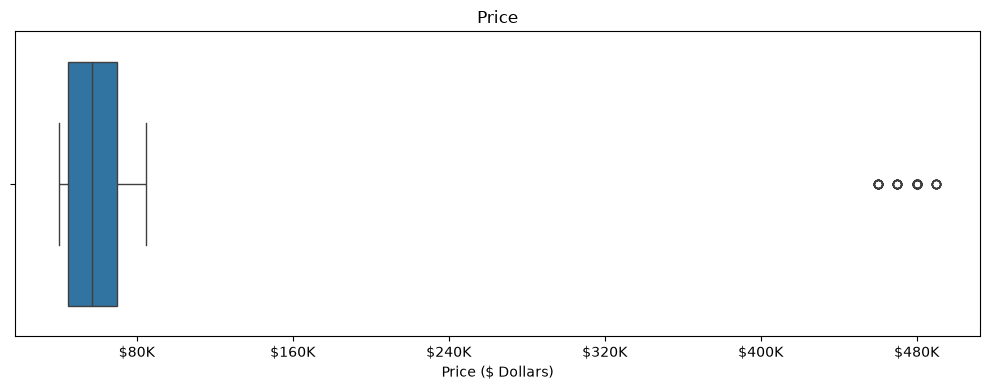

In [441]:
# intial boxplot to identify existing outliers 
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(x=df_clean["Initial Cost"], ax=ax)

ax.set_title("Price")
ax.set_xlabel("Price ($ Dollars)")

# Format tick labels as $65K
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

# Limit to roughly 8 ticks
ax.xaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
plt.show()

In [442]:
# following IQR rule finding the outliers
price = df_clean["Initial Cost"]

# IQR rule
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (price < q1 - 1.5 * iqr) | (price > q3 + 1.5 * iqr)
df_clean = df_clean[~iqr_outliers].reset_index(drop=True)
print(f"IQR rule:        keep {q1 - 1.5 * iqr:,.1f} to {q3 + 1.5 * iqr:,.1f} Dollars -> removes {iqr_outliers.sum():,} listings")


IQR rule:        keep 7,500.0 to 107,500.0 Dollars -> removes 59 listings


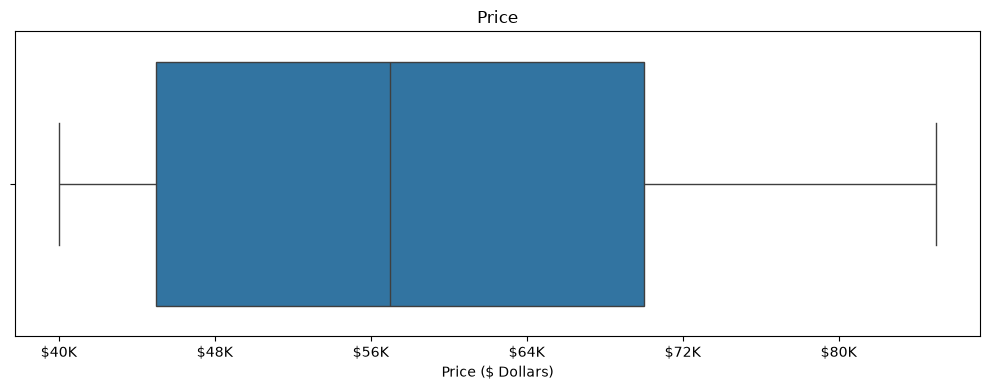

In [443]:
# removing outliers
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(x=df_clean["Initial Cost"], ax=ax)

ax.set_title("Price")
ax.set_xlabel("Price ($ Dollars)")

# Format tick labels as $65K
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

# Limit to roughly 8 ticks
ax.xaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
plt.show()

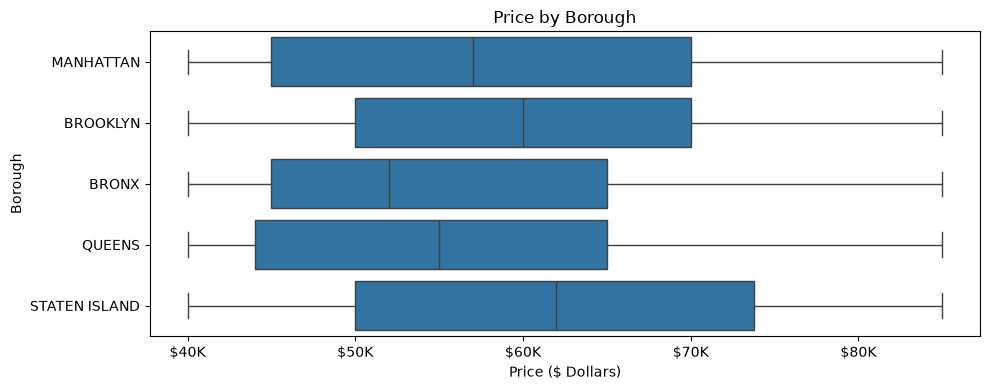

In [444]:
# finding average median cost for each borough
fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(data=df_clean, x="Initial Cost", y="Borough", ax=ax)

ax.set_title("Price by Borough")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

plt.tight_layout()
plt.show()

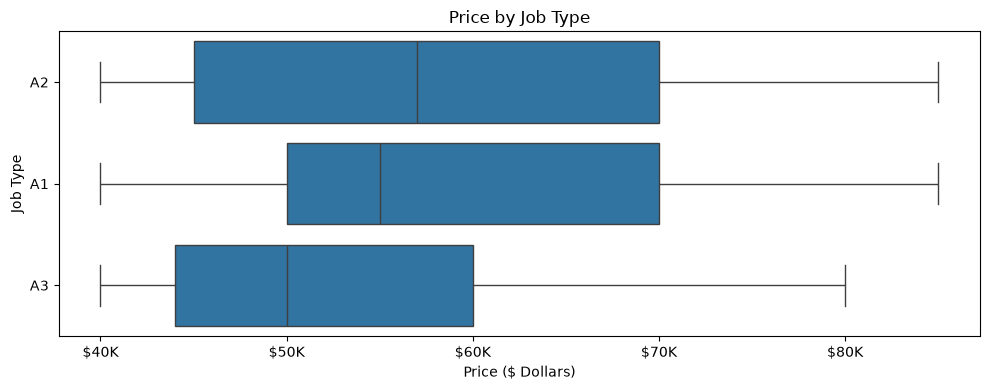

In [445]:
# finding average median cost for each Job Type
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(data=df_clean, x="Initial Cost", y="Job Type", ax=ax)

ax.set_title("Price by Job Type")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

plt.tight_layout()
plt.show()

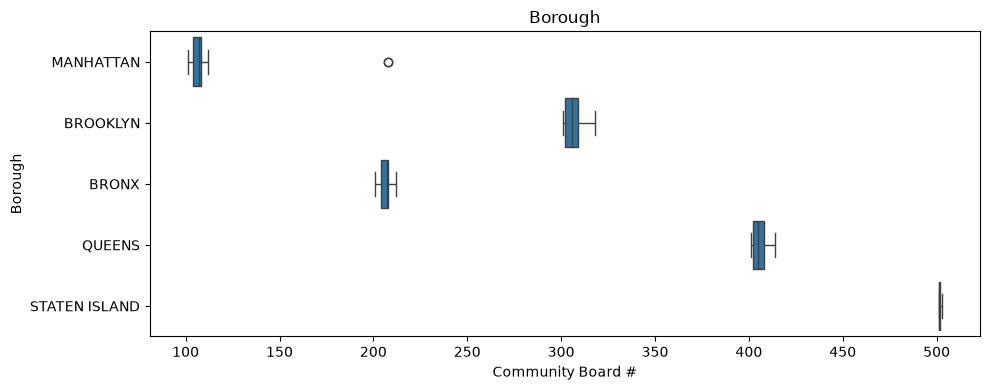

In [446]:
# Comparing Boroughs to Board # to identify mistakes
df_clean["Community - Board"] = pd.to_numeric(
    df_clean["Community - Board"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(data=df_clean, x="Community - Board", y="Borough", ax=ax)

ax.set_title("Borough")
ax.set_xlabel("Community Board #")

plt.tight_layout()
plt.show()

In [447]:
# removing data with crucial information
rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["Initial Cost"]).reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean):,} listings without Initial Cost")

rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["Borough"]).reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean):,} listings without Borough")

Removed 0 listings without Initial Cost
Removed 0 listings without Borough


In [448]:
#
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 19554 entries, 0 to 19553
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Job #                  19554 non-null  int64  
 1   Borough                19554 non-null  str    
 2   House #                19554 non-null  str    
 3   Street Name            19554 non-null  str    
 4   Block                  19554 non-null  int64  
 5   Lot                    19554 non-null  int64  
 6   Bin #                  19554 non-null  int64  
 7   Job Type               19554 non-null  str    
 8   Community - Board      19554 non-null  int64  
 9   Fully Permitted        15577 non-null  str    
 10  Initial Cost           19554 non-null  float64
 11  Zoning Dist1           17460 non-null  str    
 12  Job Description        19554 non-null  str    
 13  Initial Cost Original  19554 non-null  Float64
dtypes: Float64(1), float64(1), int64(5), str(7)
memory usage: 2.1 MB


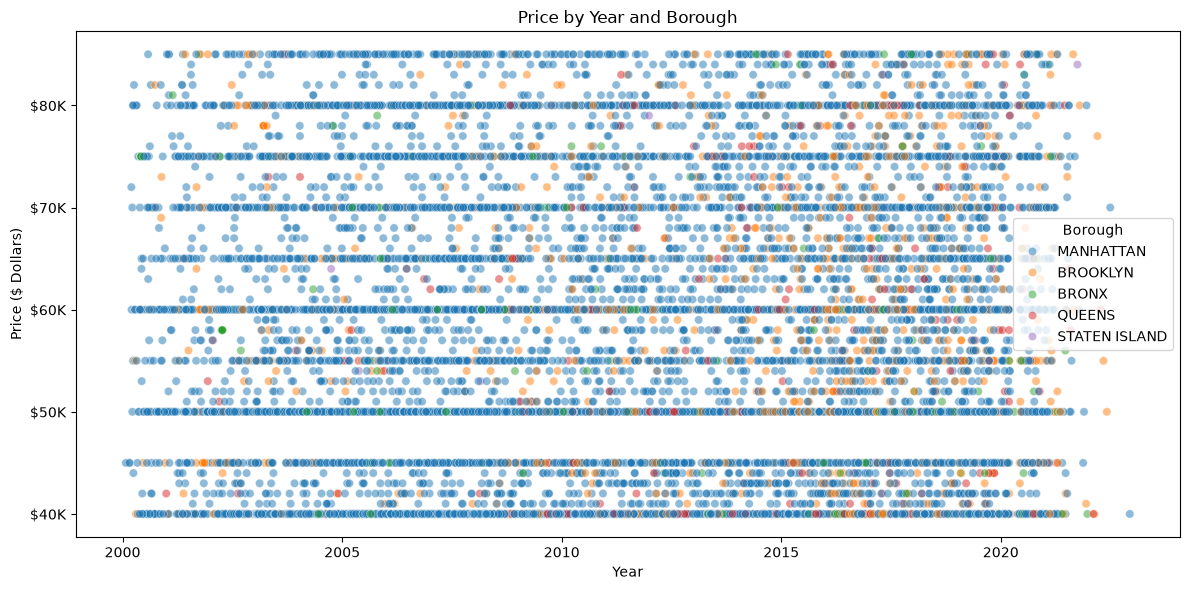

In [449]:
# Scatter Plot comparing year, cost and all boroughs
# 1. Format the date
plot_df = plot_df.copy()
plot_df["Date"] = pd.to_datetime(plot_df["Fully Permitted"], format="%m/%d/%Y", errors="coerce")

# 2. Scatter plot
fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(data=plot_df, x="Date", y="Initial Cost", hue="Borough", alpha=0.5, ax=ax)

ax.set_title("Price by Year and Borough")
ax.set_xlabel("Year")
ax.set_ylabel("Price ($ Dollars)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"${y/1000:.0f}K"))

# 3.Show only years on the x-axis
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

In [450]:
# Prepare a copy of the cleaned data for the EDA charts
eda_df = df_clean.copy()

# Full date and year from "Fully Permitted"
eda_df["Date"] = pd.to_datetime(eda_df["Fully Permitted"], format="%m/%d/%Y", errors="coerce")
eda_df["Year"] = eda_df["Date"].dt.year

# Zoning type = first letter of the zoning district (R = residential, C = commercial, M = manufacturing)
eda_df["Zoning Type"] = eda_df["Zoning Dist1"].str[0]

# Reusable "$65K" label format
k_format = FuncFormatter(lambda v, pos: f"${v/1000:.0f}K")

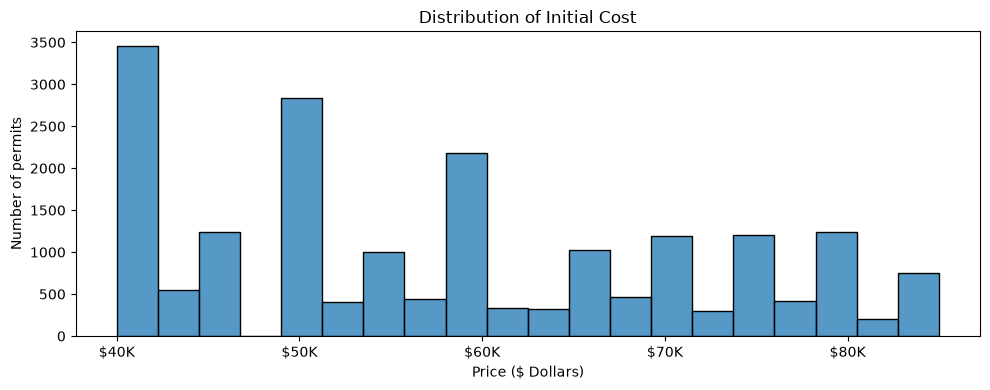

In [451]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.histplot(eda_df["Initial Cost"], bins=20, ax=ax)

ax.set_title("Distribution of Initial Cost")
ax.set_xlabel("Price ($ Dollars)")
ax.set_ylabel("Number of permits")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
plt.show()

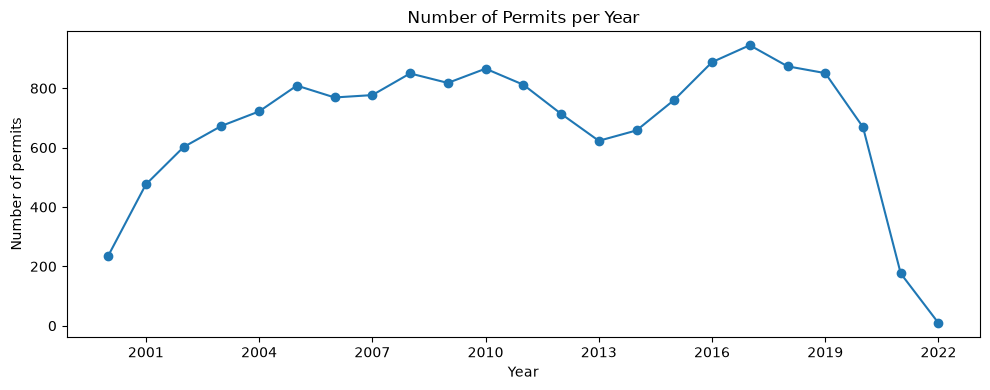

In [452]:
permits_per_year = eda_df["Year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(permits_per_year.index, permits_per_year.values, marker="o")

ax.set_title("Number of Permits per Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of permits")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

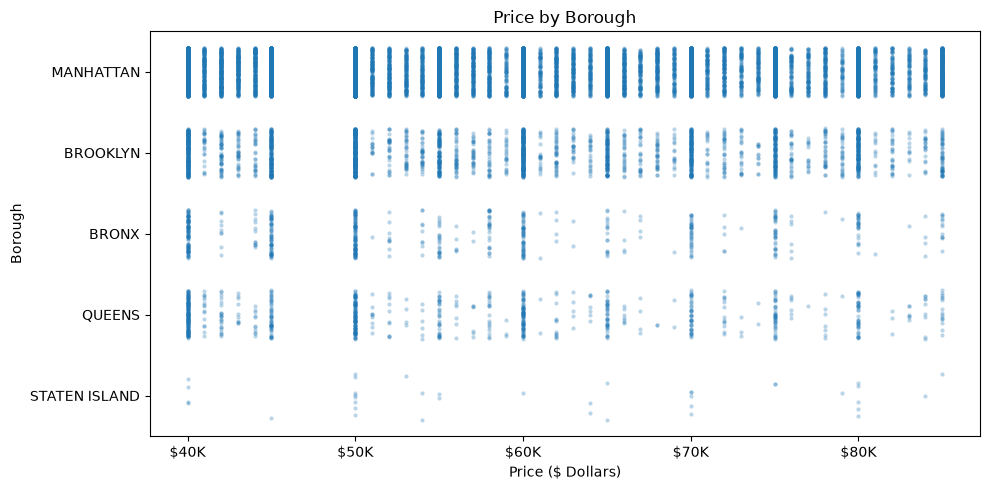

In [453]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.stripplot(data=eda_df, x="Initial Cost", y="Borough", jitter=0.3, alpha=0.3, size=3, ax=ax)

ax.set_title("Price by Borough")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
plt.show()

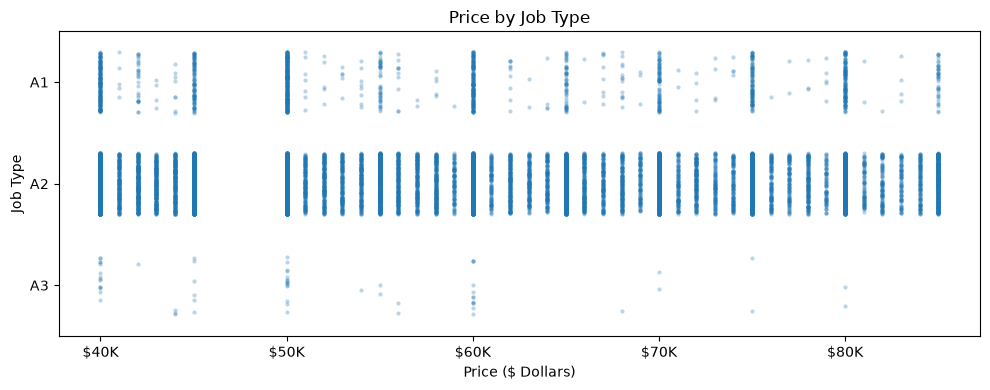

In [454]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.stripplot(data=eda_df, x="Initial Cost", y="Job Type", order=["A1", "A2", "A3"],
              jitter=0.3, alpha=0.3, size=3, ax=ax)

ax.set_title("Price by Job Type")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
plt.show()

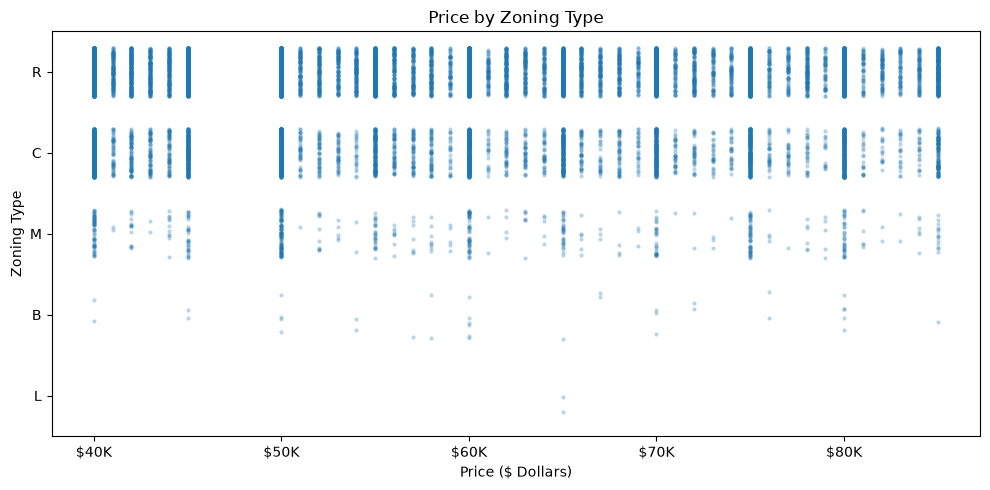

In [455]:
zoning_order = eda_df["Zoning Type"].value_counts().index

fig, ax = plt.subplots(figsize=(10, 5))

sns.stripplot(data=eda_df, x="Initial Cost", y="Zoning Type", order=zoning_order,
              jitter=0.3, alpha=0.3, size=3, ax=ax)

ax.set_title("Price by Zoning Type")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
plt.show()

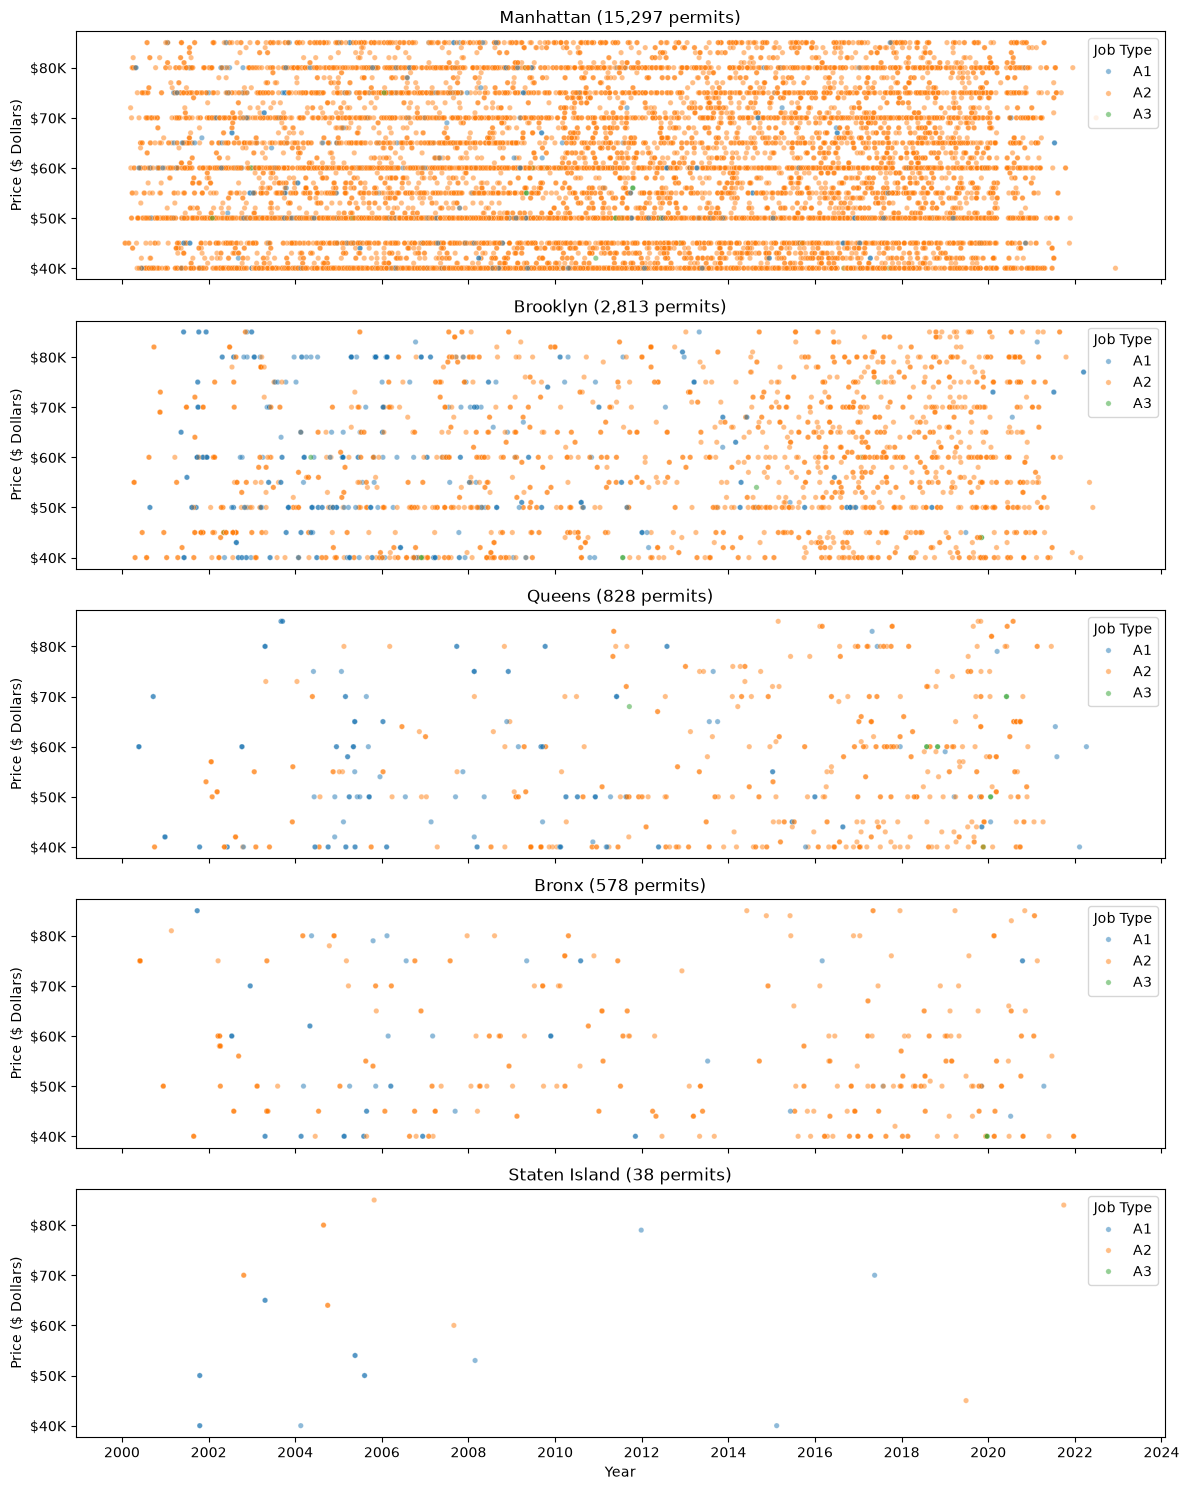

In [456]:
boroughs = eda_df["Borough"].value_counts().index

fig, axes = plt.subplots(len(boroughs), 1, figsize=(12, 3 * len(boroughs)), sharex=True, sharey=True)

for ax, borough in zip(axes, boroughs):
    data = eda_df[eda_df["Borough"] == borough]

    sns.scatterplot(data=data, x="Date", y="Initial Cost", hue="Job Type",
                    hue_order=["A1", "A2", "A3"], alpha=0.5, s=15, ax=ax)

    ax.set_title(f"{borough.title()} ({len(data):,} permits)")
    ax.set_xlabel("Year")
    ax.set_ylabel("Price ($ Dollars)")
    ax.yaxis.set_major_formatter(k_format)
    ax.legend(title="Job Type", loc="upper right")

axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

In [458]:
def cost_boxplot(column, title):
    # Only rows that have a value in this column
    data = eda_df.dropna(subset=[column])

    # Order categories from highest to lowest median cost
    order = data.groupby(column)["Initial Cost"].median().sort_values(ascending=False).index
    counts = data[column].value_counts()

    fig, ax = plt.subplots(figsize=(10, 0.8 * len(order) + 1.5))

    sns.boxplot(data=data, x="Initial Cost", y=column, order=order,
                showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"},
                ax=ax)

    # Add the number of permits to each label
    ax.set_yticklabels([f"{c}  (n={counts[c]:,})" for c in order])

    ax.set_title(title)
    ax.set_xlabel("Price ($ Dollars)")
    ax.set_ylabel(column)
    ax.xaxis.set_major_formatter(k_format)

    plt.tight_layout()
    plt.show()

/var/folders/7x/4mr6dq0s3ll7hrz5x39p97680000gp/T/ipykernel_53734/2012336361.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([f"{c}  (n={counts[c]:,})" for c in order])


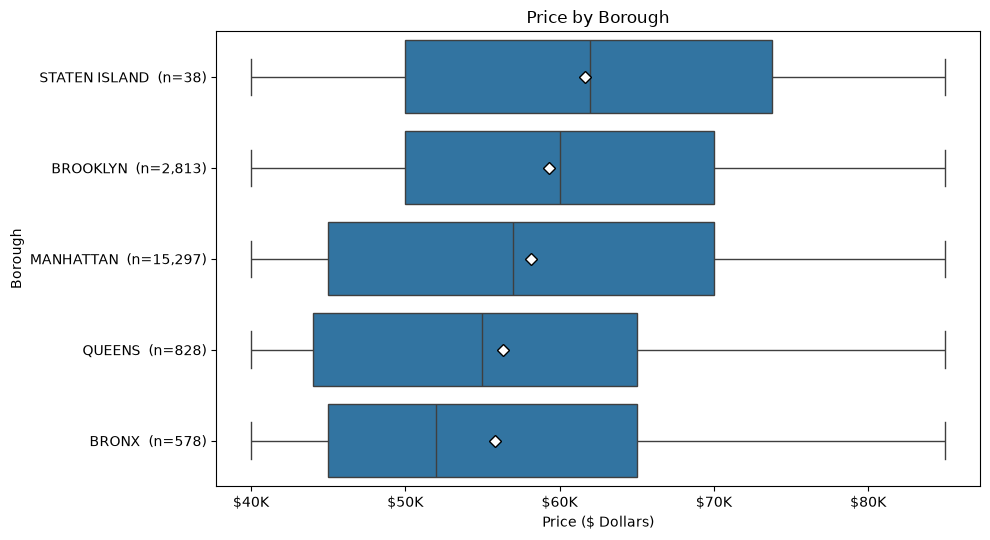

In [459]:
cost_boxplot("Borough", "Price by Borough")

/var/folders/7x/4mr6dq0s3ll7hrz5x39p97680000gp/T/ipykernel_53734/2012336361.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([f"{c}  (n={counts[c]:,})" for c in order])


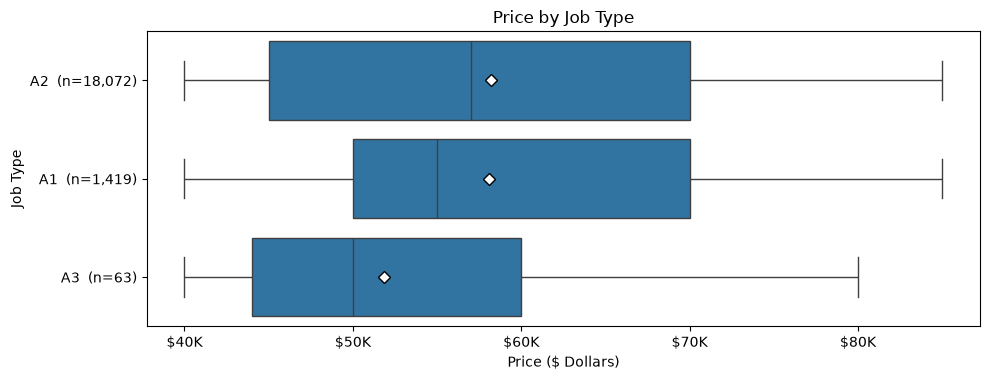

In [460]:
cost_boxplot("Job Type", "Price by Job Type")

/var/folders/7x/4mr6dq0s3ll7hrz5x39p97680000gp/T/ipykernel_53734/2012336361.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([f"{c}  (n={counts[c]:,})" for c in order])


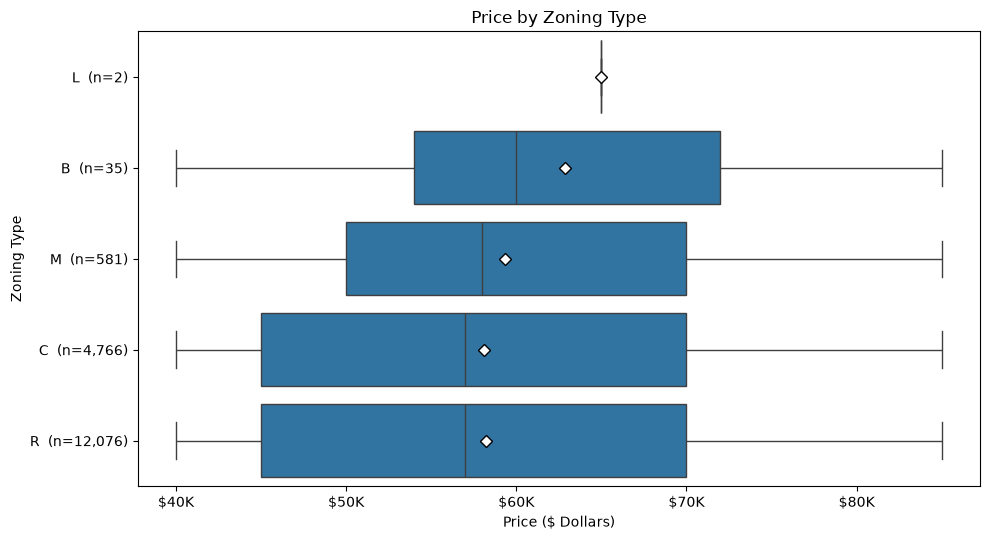

In [461]:
cost_boxplot("Zoning Type", "Price by Zoning Type")

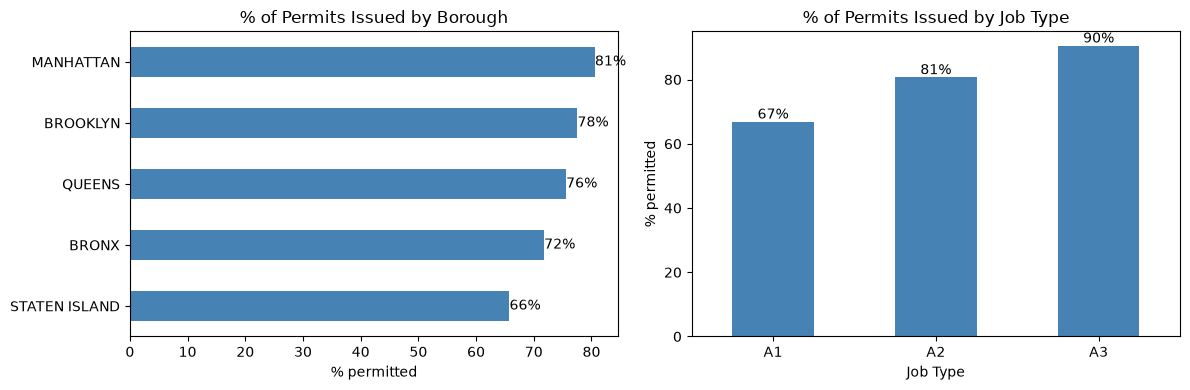

In [462]:
# True if the permit has a "Fully Permitted" date, False if it's empty
eda_df["Is Permitted"] = eda_df["Fully Permitted"].notna()
eda_df["Status"] = eda_df["Is Permitted"].map({True: "Permitted", False: "Not permitted"})

# % of permits issued, per borough and per job type
rate_borough = eda_df.groupby("Borough")["Is Permitted"].mean().mul(100).sort_values()
rate_job = eda_df.groupby("Job Type")["Is Permitted"].mean().mul(100)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rate_borough.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("% of Permits Issued by Borough")
axes[0].set_xlabel("% permitted")
axes[0].set_ylabel("")
axes[0].bar_label(axes[0].containers[0], fmt="%.0f%%")

rate_job.plot(kind="bar", ax=axes[1], color="steelblue", rot=0)
axes[1].set_title("% of Permits Issued by Job Type")
axes[1].set_ylabel("% permitted")
axes[1].set_xlabel("Job Type")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f%%")

plt.tight_layout()
plt.show()

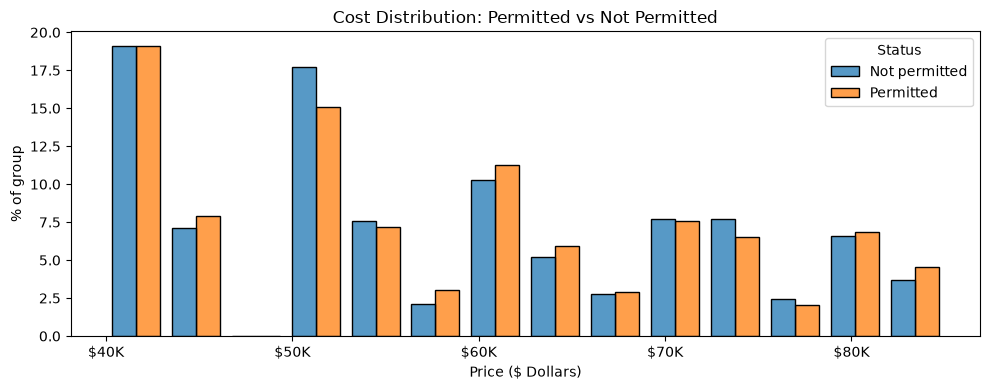

In [463]:
# Do permitted and not permitted jobs have different costs?
fig, ax = plt.subplots(figsize=(10, 4))

sns.histplot(data=eda_df, x="Initial Cost", hue="Status", stat="percent",
             common_norm=False, multiple="dodge", bins=14, shrink=0.8, ax=ax)

ax.set_title("Cost Distribution: Permitted vs Not Permitted")
ax.set_xlabel("Price ($ Dollars)")
ax.set_ylabel("% of group")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
plt.show()

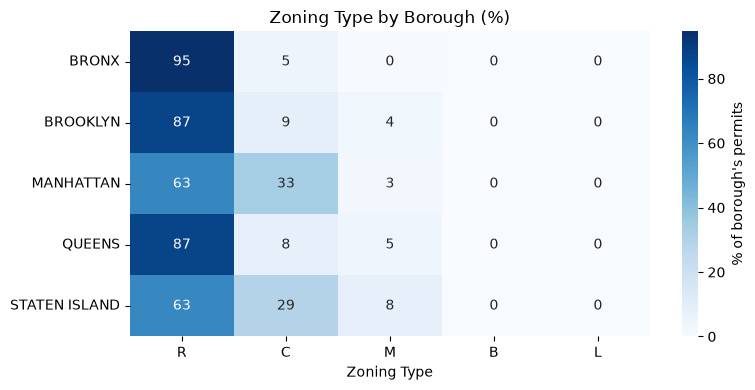

In [464]:
# % of each borough's permits in each zoning type
zoning_table = pd.crosstab(eda_df["Borough"], eda_df["Zoning Type"], normalize="index") * 100
zoning_table = zoning_table[eda_df["Zoning Type"].value_counts().index]   # most common zoning first

fig, ax = plt.subplots(figsize=(8, 4))

sns.heatmap(zoning_table, annot=True, fmt=".0f", cmap="Blues",
            cbar_kws={"label": "% of borough's permits"}, ax=ax)

ax.set_title("Zoning Type by Borough (%)")
ax.set_xlabel("Zoning Type")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

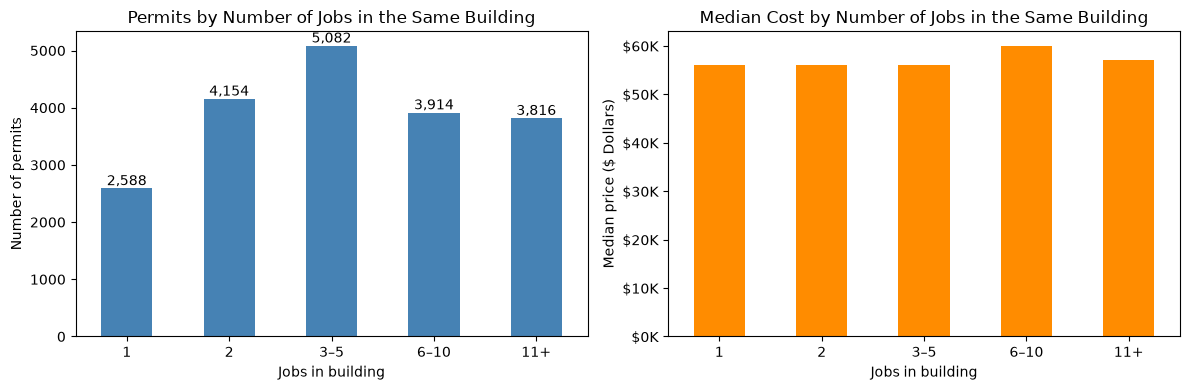

In [465]:
# Remove placeholder building IDs (NYC uses 1000000, 2000000... when the ID is unknown)
buildings = eda_df[eda_df["Bin #"] % 1_000_000 != 0].copy()

# How many jobs each building has in the data
buildings["Jobs in Building"] = buildings.groupby("Bin #")["Job #"].transform("count")
buildings["Job Group"] = pd.cut(buildings["Jobs in Building"],
                                bins=[0, 1, 2, 5, 10, 10_000],
                                labels=["1", "2", "3–5", "6–10", "11+"])

summary = buildings.groupby("Job Group", observed=True).agg(
    Permits=("Job #", "count"),
    Median_Cost=("Initial Cost", "median"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

summary["Permits"].plot(kind="bar", ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Permits by Number of Jobs in the Same Building")
axes[0].set_xlabel("Jobs in building")
axes[0].set_ylabel("Number of permits")
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}")

summary["Median_Cost"].plot(kind="bar", ax=axes[1], color="darkorange", rot=0)
axes[1].set_title("Median Cost by Number of Jobs in the Same Building")
axes[1].set_xlabel("Jobs in building")
axes[1].set_ylabel("Median price ($ Dollars)")
axes[1].yaxis.set_major_formatter(k_format)

plt.tight_layout()
plt.show()

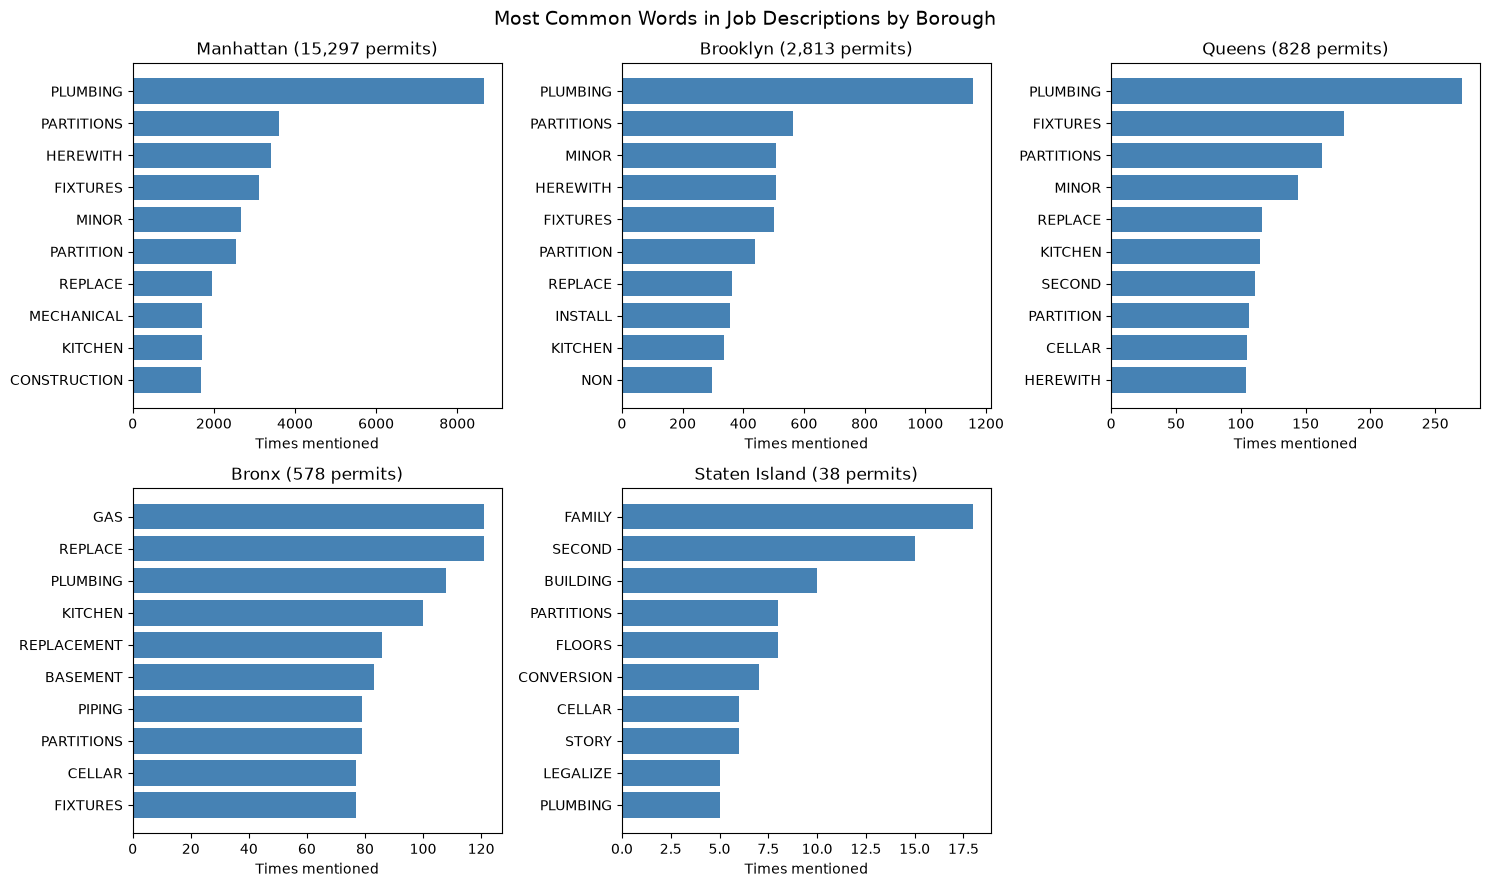

In [466]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Words to ignore: common English words + words that appear in almost every description
extra_stopwords = {
    "APARTMENT", "APARTMENTS", "APT", "RENOVATION", "RENOVATE", "EXISTING",
    "PROPOSED", "PROPOSE", "CHANGE", "USE", "EGRESS", "OCCUPANCY", "FILING",
    "HEREBY", "APPLICATION", "WORK", "FLOOR", "NEW", "INTERIOR", "AMP",
    "PER", "PLANS", "FILED", "TYPE", "SCOPE", "INCLUDE", "INCLUDES", "INCLUDING"}
stopwords = {w.upper() for w in ENGLISH_STOP_WORDS} | extra_stopwords

def top_words(texts, n=10):
    words = texts.str.upper().str.findall(r"[A-Z]{3,}").explode()
    words = words[~words.isin(stopwords)]
    return words.value_counts().head(n)

boroughs = eda_df["Borough"].value_counts().index

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, borough in zip(axes, boroughs):
    descriptions = eda_df.loc[eda_df["Borough"] == borough, "Job Description"].dropna()
    words = top_words(descriptions).sort_values()

    ax.barh(words.index, words.values, color="steelblue")
    ax.set_title(f"{borough.title()} ({len(descriptions):,} permits)")
    ax.set_xlabel("Times mentioned")

axes[-1].axis("off")   # 5 boroughs, 6 spaces: hide the empty one

plt.suptitle("Most Common Words in Job Descriptions by Borough", fontsize=14)
plt.tight_layout()
plt.show()